# PRO/PAO amplitude demo

In [ ]:
"""
File Name: pro_pao_amplitude.ipynb

Author:
    Federico Minati
    B-Open Solutions srl

Date: August 2025

Description:
------------
This notebook processes Sentinel-1 data to generate Analysis-Ready Data (ARD) products, specifically Precise azimuth offset.
Options and configuration parameters about some processing steps can be set
by the user.

"""

In [6]:
import pstools.io
import coregistration.slc
import xarray as xr
import numpy as np
import pandas as pd
import os
from scipy.constants import speed_of_light
import s3fs
import matplotlib.pyplot as plt
fs = s3fs.S3FileSystem(anon=True)


In [3]:

in_data = 's3://bopen-sar/ARD-ROSE-L/SENTINEL/Greenland/112/SENTINEL1_112_20230710_20230722_HH'
# in_data = 's3://bopen-sar/ARD-ROSE-L/SENTINEL/Greenland/119/SENTINEL1_119_20230710_20230722_HH'
dirname = os.path.dirname(in_data)
basename = os.path.basename(in_data)
ml = {'az': 16, 'rg': 64}

## open CLC propduct

In [4]:
slcs = coregistration.slc.lazy_open(in_data)
# burst = pstools.io.read(os.path.join(in_data, 'bursts'), consolidate_metadata=False)

2025-09-01 19:33:35 [debug    ] Looking for global client (None)
2025-09-01 19:33:35 [warning  ] No global client found a new one will be created
2025-09-01 19:33:35 [debug    ] <Cluster info: type=LOCAL, n_jobs=8, job_memory=31620148016>


In [5]:
az_min = []
rg_min = []
dtrg = []
dtaz = []
for _, v in slcs.bursts.items():
    annot = v.coreg.cstack.attrs
    az_min.append(v.coreg.azimuth_time.min().values)
    rg_min.append(v.coreg.slant_range_time.min().values) 
    dtaz.append(annot["RMA"]["INCA"]["TimeCAPoly"]["Coefs"][1] * annot["Grid"]["Col"]["SS"])
    dtrg.append(2*annot["Grid"]["Row"]["SS"] / speed_of_light)

az_min = np.array(az_min).min()
rg_min = np.array(rg_min).min()
dtrg = np.array(dtrg).mean()
dtaz = np.array(dtaz).mean()
az_min, rg_min, dtrg, dtaz

(numpy.datetime64('2023-07-10T09:13:48.336512634'),
 0.005658604337719389,
 1.554116558005821e-08,
 0.002055556299999998)

In [8]:
import pstools.computation
import coregistration.matching

slcs_burst = slcs.bursts['iw2_239128']


/home/ubuntu/miniconda/envs/insar-stable/lib/python3.11/site-packages/dask/dataframe/_pyarrow_compat.py:15: FutureWarning: Minimal version of pyarrow will soon be increased to 14.0.1. You are using 12.0.1. Please consider upgrading.
  warnings.warn(


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_shift_vectors(img, x_map, y_map, cohe_map, cohe_th=0.3, step=10, scale=1.0, outfile=None):
    """
    Plot shift vectors (x_map, y_map) as arrows over a background image.

    Args:
        background (2D np.ndarray): Background image.
        x_map (2D np.ndarray): X component of shift vectors.
        y_map (2D np.ndarray): Y component of shift vectors.
        step (int): Grid step to reduce number of arrows.
        scale (float): Quiver scale factor.
    """
    assert img.shape == x_map.shape == y_map.shape, "All maps must have the same shape"
    h, w = img.shape

    valid_points = np.where(cohe_map > cohe_th)
    
    y_s, x_s = valid_points
    
    y_e = y_s + y_map[y_s, x_s]
    x_e = x_s + x_map[y_s, x_s]
    
    l = np.sqrt((x_e - x_s)**2 + (y_e - y_s)**2)
    
    # Plot
    plt.figure(figsize=(20, 16))
    plt.imshow(img, cmap='gray')
    plt.quiver(x_s, y_s, x_map[y_s, x_s] / l, y_map[y_s, x_s] / l, l, cmap=plt.cm.jet, angles='xy', scale_units='xy', scale=scale, width=0.0015)
    plt.title("Displacement Vectors Over Background")
    plt.xlabel("X")
    plt.ylabel("Y")
    
    # plt.gca().invert_yaxis()  # match image coordinates
    plt.grid(False)
    plt.tight_layout()
    plt.savefig(outfile, dpi=300)


 ## compute disparity map

In [ ]:
disparities = {}
for k, slcs_burst in slcs.bursts.items():
    reference_date = '2023-07-10'
    y_size=16
    x_size=64

    try:
        disparity = pstools.computation.map_blocks(
            coregistration.matching.compute_pearson_coefficient,
            slcs_burst.coreg.cstack.chunk(acquisition_date=-1, azimuth_time=y_size, slant_range_time=x_size),
            args=(reference_date),
            kwargs={
                "mode": "amplitude",
                "wsearch": [5, 5],
                "forward": False,
                "dim": [1, 1],
                "type": "times",
            },
            client_options={'type': 'LOCAL'},
            fix_memory_leak=False,
        )
    
        disparities[k] = disparity
        
        x_radar = np.floor((disparity.x - rg_min) / dtrg / x_size).astype('int32').values
        y_radar = np.floor(((disparity.y - az_min).astype('float64') / 1e9) / dtaz / y_size).astype('int32').values

        x_offset = disparity.sel(variable='dx', acquisition_date='2023-07-22').values / disparity.attrs['pixel_to_time'][1]
        y_offset = disparity.sel(variable='dy', acquisition_date='2023-07-22').values / disparity.attrs['pixel_to_time'][0]
        cohe = disparity.sel(variable='cohe', acquisition_date='2023-07-22').values

        c_map = np.full((y_radar.max() + 1, x_radar.max() + 1), fill_value=np.nan)
        x_map = np.full((y_radar.max() + 1, x_radar.max() + 1), fill_value=np.nan)
        y_map = np.full((y_radar.max() + 1, x_radar.max() + 1), fill_value=np.nan)

        c_map[y_radar, x_radar] = cohe
        x_map[y_radar, x_radar] = x_offset
        y_map[y_radar, x_radar] = y_offset
        
        plot_shift_vectors(c_map, x_map, y_map, c_map, cohe_th=0.4, scale=0.5, outfile=f'/scratch/external/ARD-ROSE-L/PRO-PAO/disparity_{k}.png')
        print(f"Processed {k} successfully.")
    except Exception as e:
        print(f"Error processing {k}: {e}")
        continue    
    
    

In [11]:
x_radar = np.floor((disparity.x - rg_min) / dtrg / x_size).astype('int32').values
y_radar = np.floor(((disparity.y - az_min).astype('float64') / 1e9) / dtaz / y_size).astype('int32').values

x_offset = disparity.sel(variable='dx', acquisition_date='2023-07-22').values / disparity.attrs['pixel_to_time'][1]
y_offset = disparity.sel(variable='dy', acquisition_date='2023-07-22').values / disparity.attrs['pixel_to_time'][0]
cohe = disparity.sel(variable='cohe', acquisition_date='2023-07-22').values


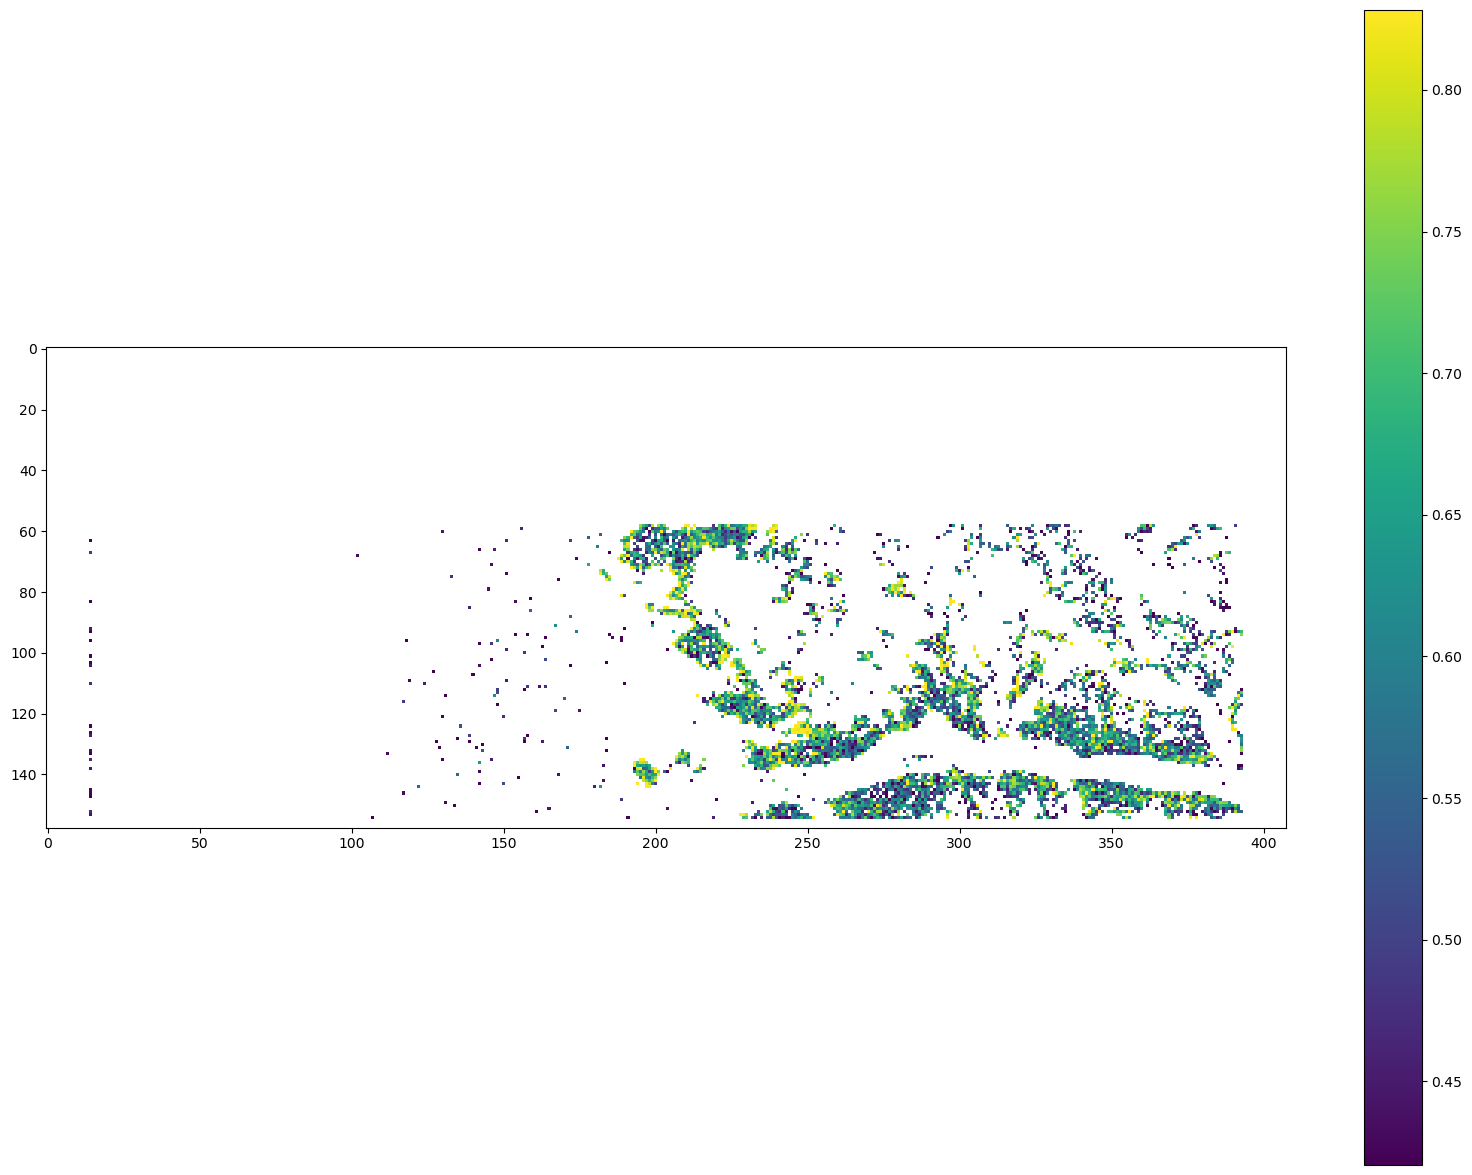

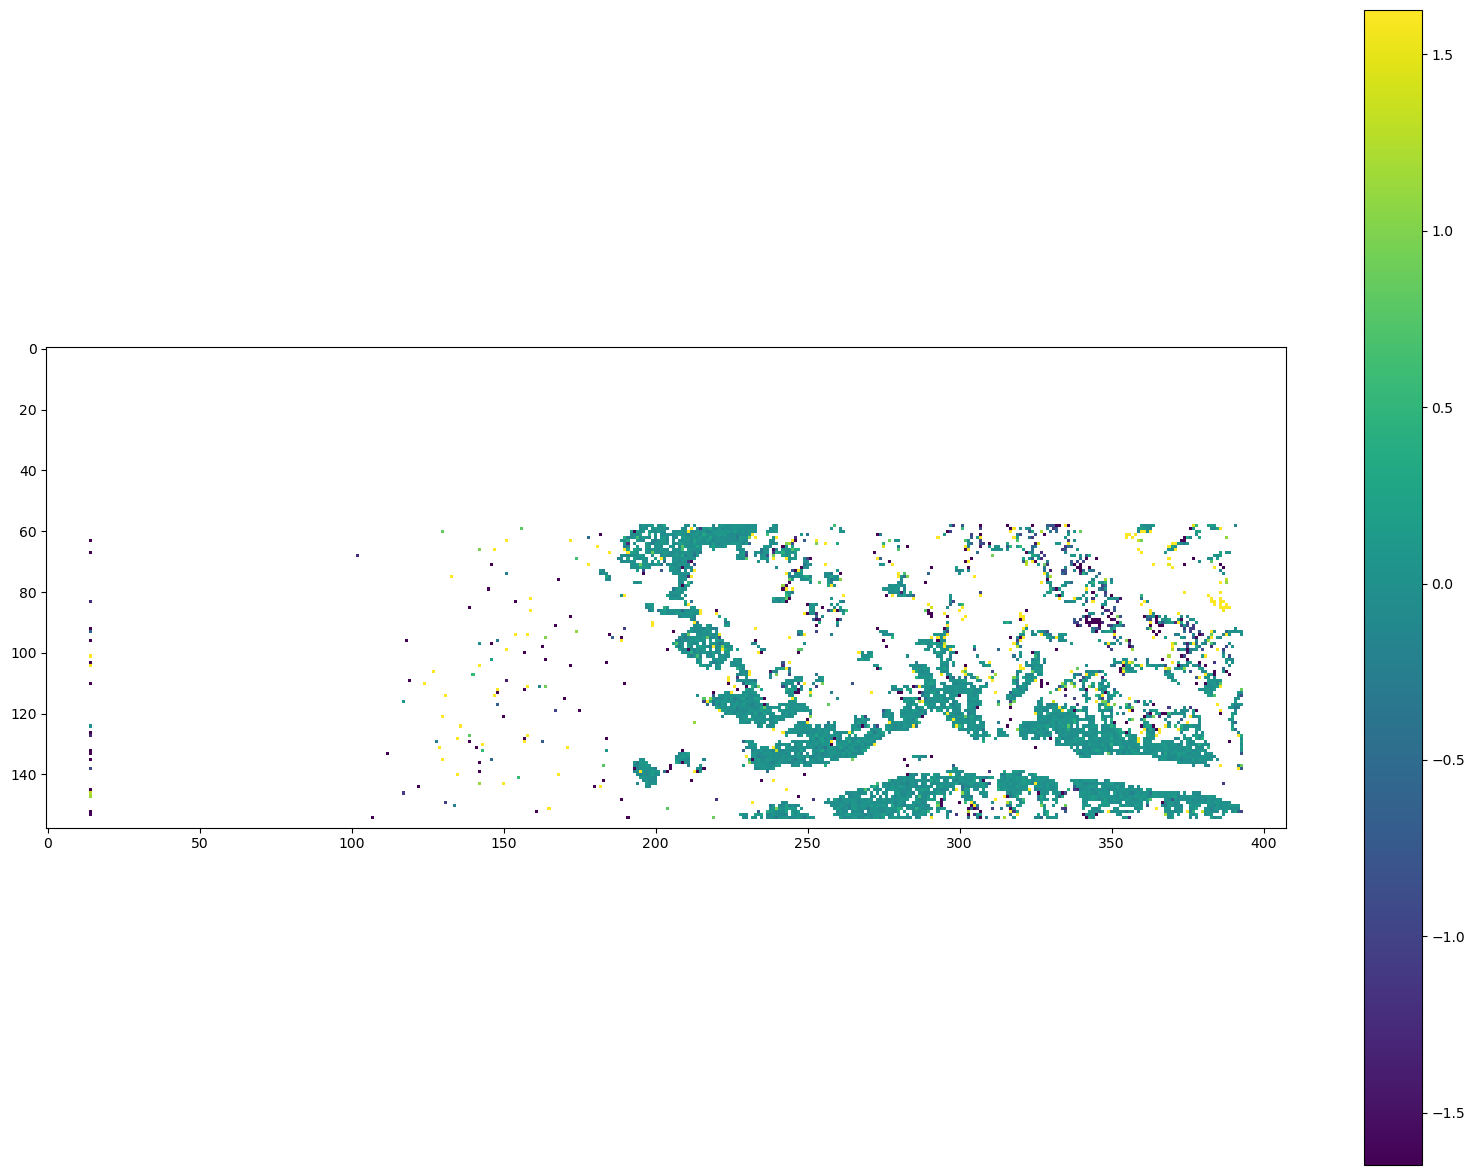

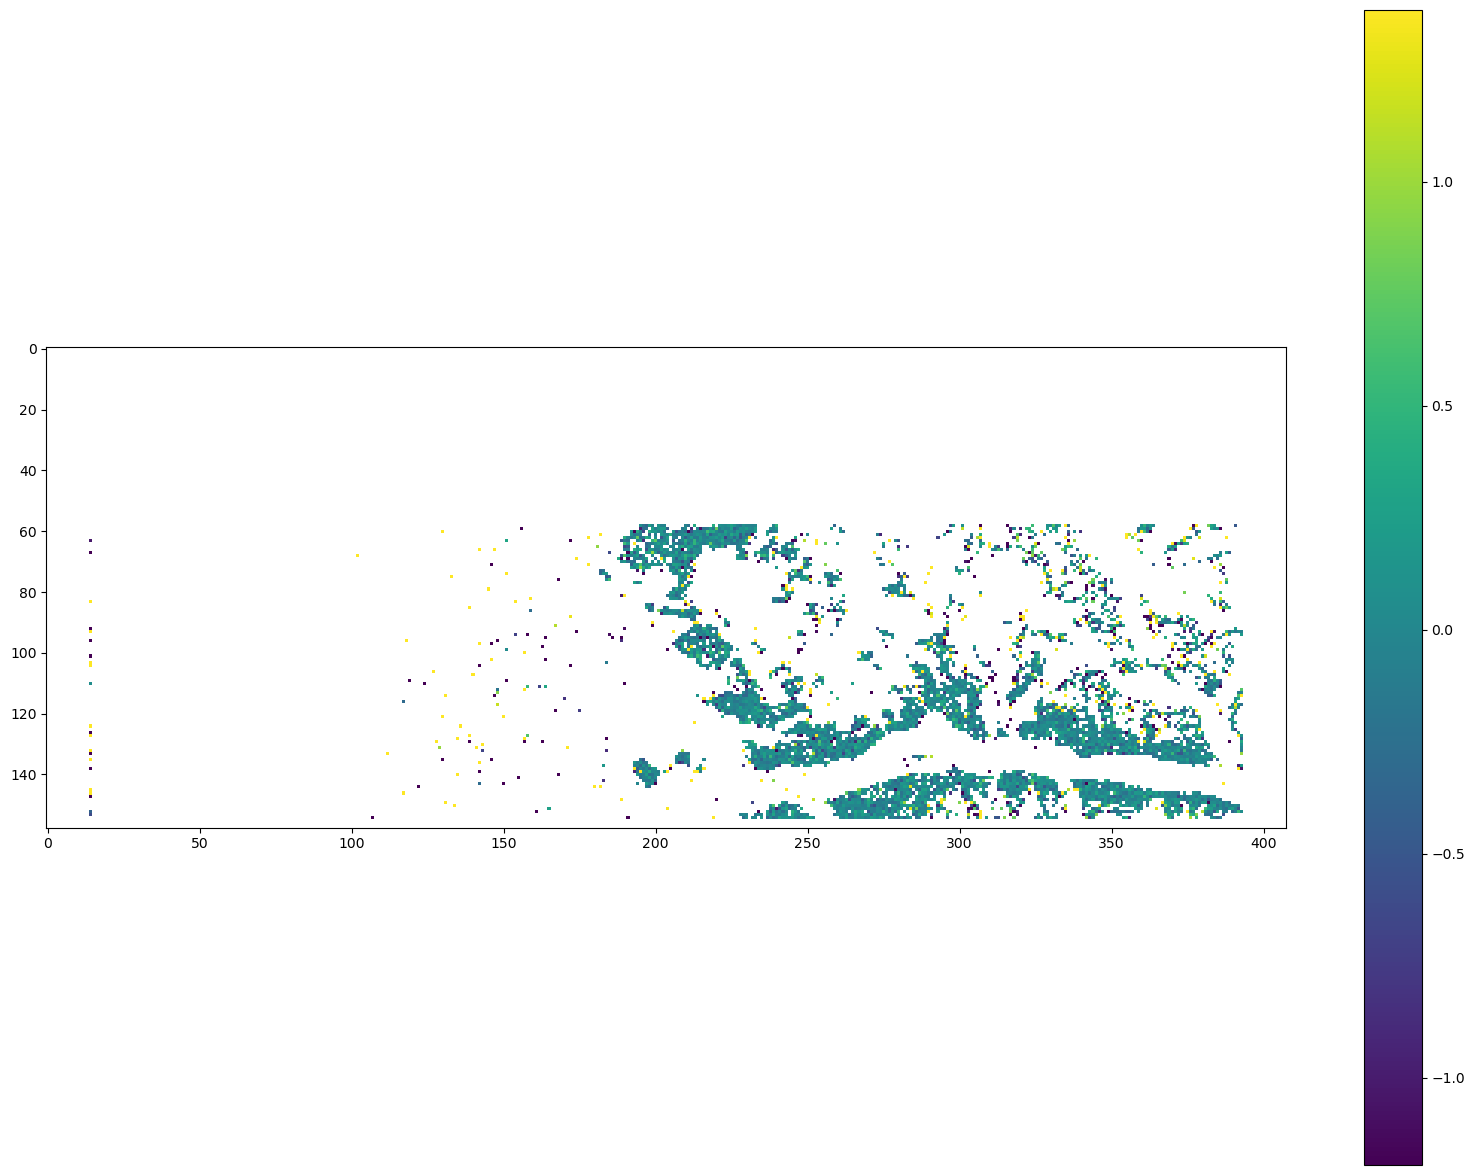

In [38]:
import matplotlib.pyplot as plt

th = 0.4
c_map = np.full((y_radar.max() + 1, x_radar.max() + 1), fill_value=np.nan)
x_map = np.full((y_radar.max() + 1, x_radar.max() + 1), fill_value=np.nan)
y_map = np.full((y_radar.max() + 1, x_radar.max() + 1), fill_value=np.nan)

c_map[y_radar, x_radar] = cohe
x_map[y_radar, x_radar] = x_offset
y_map[y_radar, x_radar] = y_offset


for vmap in [c_map, x_map, y_map]:
    _vmap = vmap.copy()
    _vmap[c_map <= th] = np.nan
    plt.figure(figsize=(20, 15))
    plt.imshow(_vmap, cmap='viridis', vmin=np.nanpercentile(_vmap, 5), vmax=np.nanpercentile(_vmap, 95))
    plt.colorbar()
    plt.show()


## Plot displacements

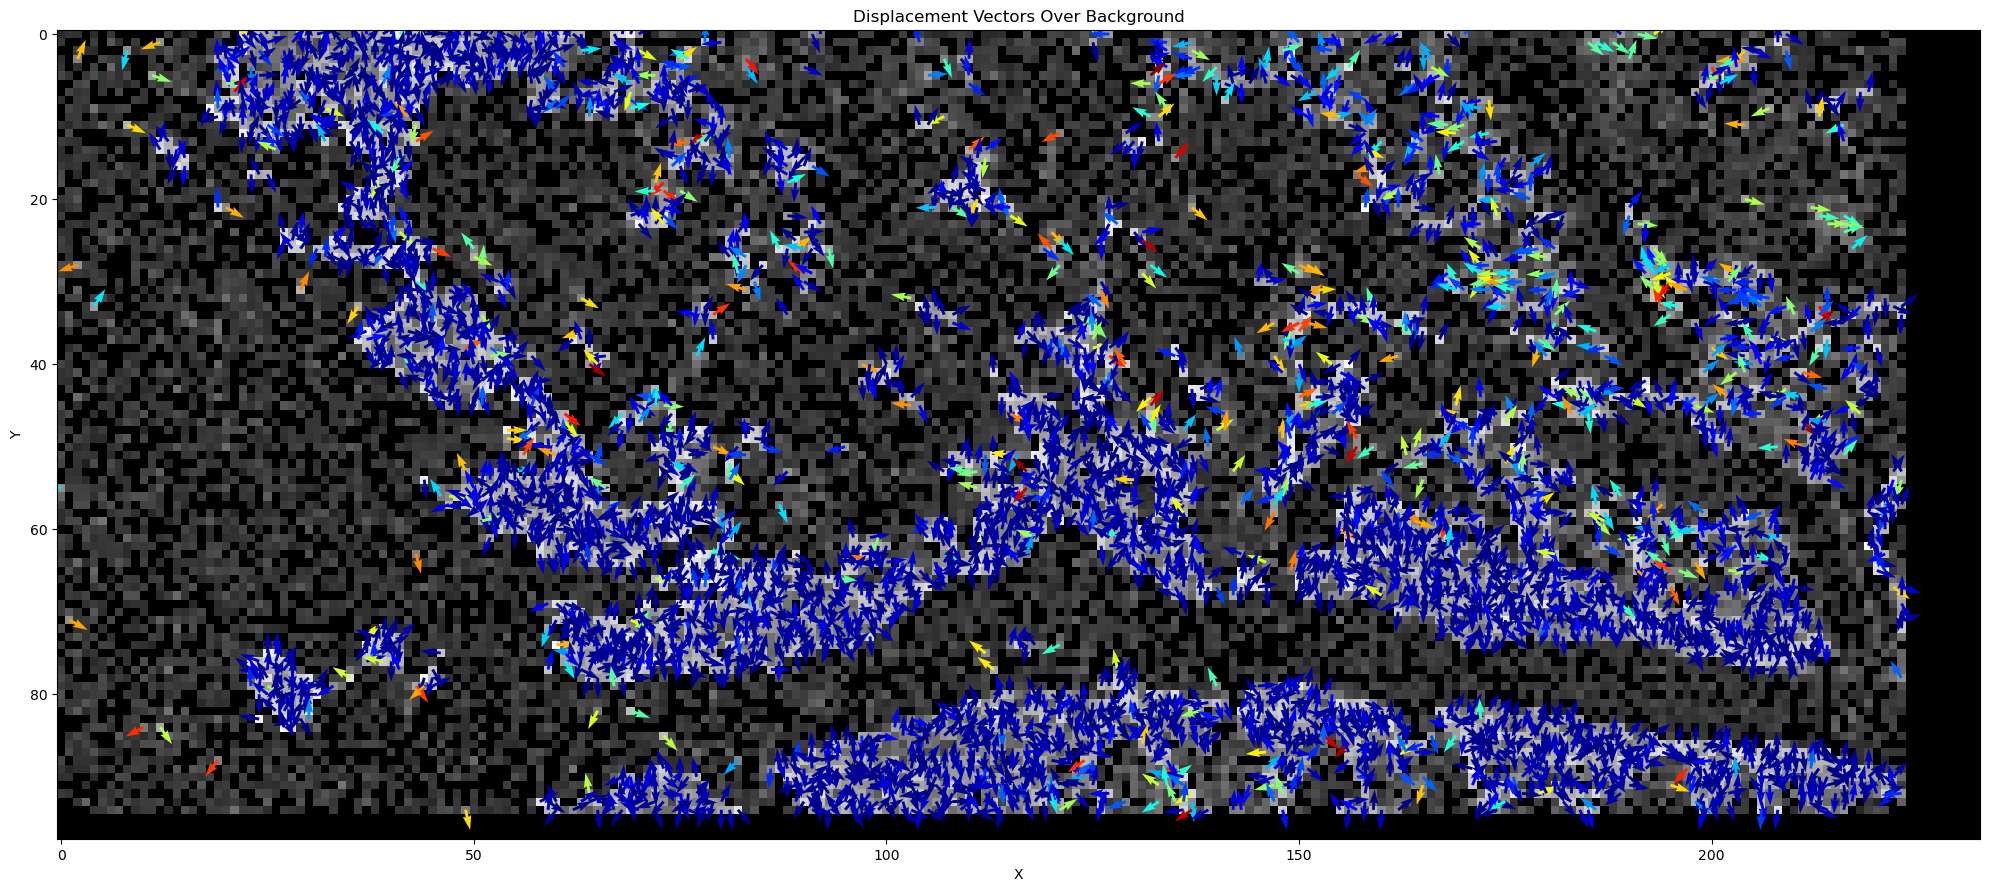

In [123]:
plot_shift_vectors(c_map[60:, 170:-5], x_map[60:, 170:-5], y_map[60:, 170:-5], c_map[60:, 170:-5], cohe_th=0.45, scale=0.4)

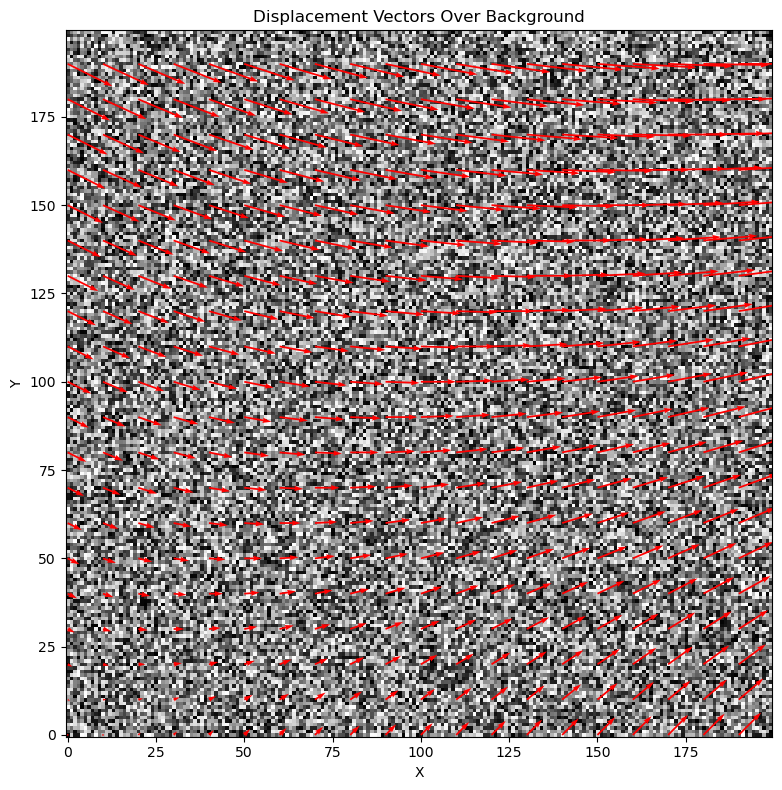

In [35]:
H, W = 200, 200
background = np.random.rand(H, W)
yy, xx = np.mgrid[0:H, 0:W]

x_map = (yy * 2 + xx) / 30
y_map = (xx - yy) / 30
plot_shift_vectors(background, x_map, y_map, step=10, scale=1)

In [16]:
import matplotlib.pyplot as plt
ind = np.where(v[:,2]< 0.3)
v[ind,:]=0


Text(0.5, 1.0, 'Disparity map dy')

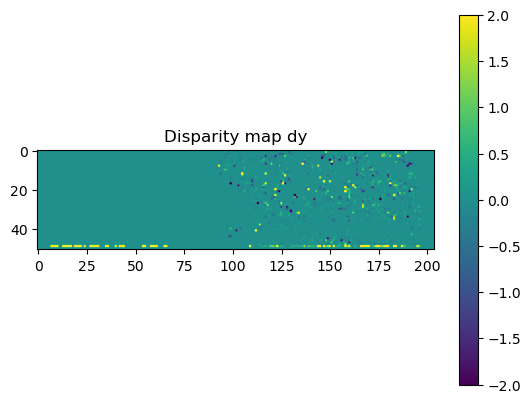

In [33]:
plt.imshow(v.reshape(51,204,5)[:,:,0].astype(float)/1e9 / dtaz, vmin=-2, vmax=2)
plt.colorbar()
plt.title('Disparity map dy')

Text(0.5, 1.0, 'Disparity map dx')

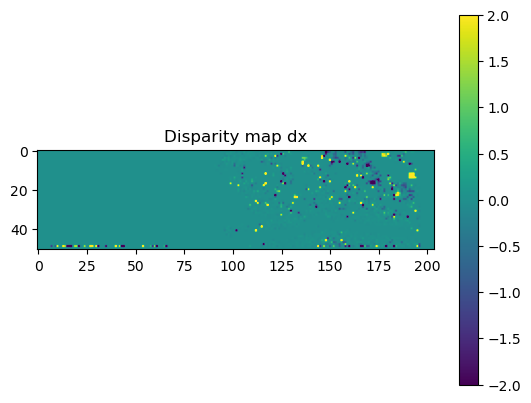

In [39]:
plt.imshow(v.reshape(51,204,5)[:,:,1].astype(float) / dtrg, vmin=-2, vmax=2)
plt.colorbar()
plt.title('Disparity map dx')

Text(0.5, 1.0, 'Disparity par5')

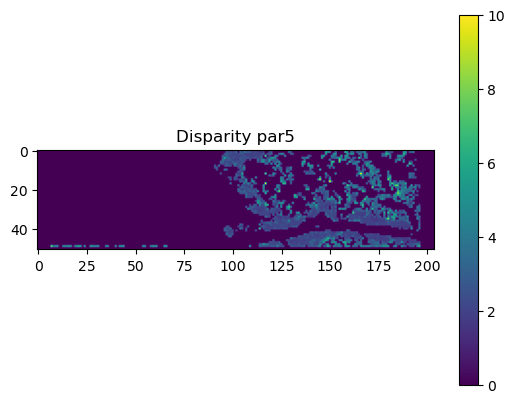

In [43]:
plt.imshow(v.reshape(51,204,5)[:,:,4], vmax=10)
plt.colorbar()
plt.title('Disparity par5')

## estimated accuracy

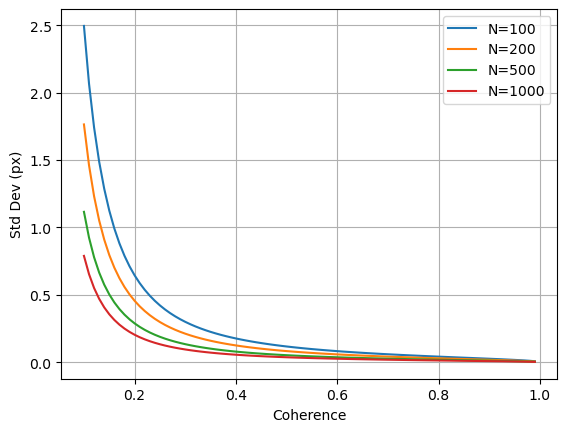

In [9]:
gamma = np.arange(10, 100, dtype='float32') / 100;

for N in [100, 200, 500, 1000]:
    sigma_i = np.sqrt(3.0 / (10 * N)) * np.sqrt(2.0 + 5.0 * gamma**2 - 7 * gamma**4) / (np.pi * gamma**2)
    plt.plot(gamma, sigma_i, label=f'N={N}')

plt.xlabel('Coherence'); plt.ylabel('Std Dev (px)');
plt.grid()
plt.legend(); plt.show()

